# Smart Inventory & Restock Prediction — Exploratory Data Analysis

This notebook explores the **processed synthetic inventory observations** in `data/processed_inventory.csv`. It describes what appears in this generated sample; it does not represent a retailer's real inventory or establish causes.

**Scope:** dataset profile, product/store availability, observed restock counts, daily and weekly trends, distributions, and descriptive relationships. No prediction target is created and no model is trained. `restock_occurred` is summarized only as an observed event count, never used as a predictor.

All summaries use observations at their recorded timestamps. A restock recorded on a row is counted for descriptive reporting of that row's day; no later rows are used to make claims about an earlier date.

## 1. Load and verify the processed dataset

The CSV stores timestamps as text. We parse them as timezone-aware UTC values before sorting and grouping. UTC provides one consistent timeline and avoids mixing local offsets.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

candidates = [Path.cwd(), Path.cwd().parent]
project_root = next((p for p in candidates if (p / "data/processed_inventory.csv").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Could not find data/processed_inventory.csv from the notebook or its parent folder.")
input_path = project_root / "data" / "processed_inventory.csv"
df = pd.read_csv(input_path)
required = {
    "product_id", "product_name", "category", "store_id", "store_location",
    "timestamp", "stock_quantity", "availability_status", "previous_stock_status",
    "days_since_last_restock", "historical_restock_count", "restock_occurred", "data_source",
}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="raise", utc=True)
df = df.sort_values(["product_id", "store_id", "timestamp"], kind="mergesort").reset_index(drop=True)
if not df["data_source"].eq("synthetic").all():
    raise ValueError("This notebook expects every row to be labeled synthetic.")
if not df["timestamp"].dt.tz:
    raise ValueError("Timestamps must be timezone-aware.")

print(f"Input: {input_path}")
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns; timestamps normalized to UTC.")
df.head()

Input: C:\Users\PC\Documents\ChatGPT\Inventory tracking\data\processed_inventory.csv
Loaded 10,800 rows and 13 columns; timestamps normalized to UTC.


## 2. Dataset dimensions, columns, types, and summary statistics

The dimension tells us how many observations and fields are available. Numeric summaries describe observed quantities; they do not explain why those values occurred.

In [2]:
print("Dimensions (rows, columns):", df.shape)
print("Unique products:", df["product_id"].nunique())
print("Unique stores:", df["store_id"].nunique())
print("Timestamp range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("\nColumn data types:")
display(df.dtypes.rename("dtype").to_frame())
print("\nMissing values by column:")
display(df.isna().sum().rename("missing_count").to_frame())
print("\nNumeric summary:")
display(df.select_dtypes(include="number").describe().T)
print("\nCategorical summary:")
display(df[["category", "availability_status", "previous_stock_status", "data_source"]].describe().T)

Dimensions (rows, columns): (10800, 13)
Unique products: 20
Unique stores: 6
Timestamp range: 2025-01-01 00:00:00+00:00 to 2025-03-31 00:00:00+00:00

Column data types:

Missing values by column:

Numeric summary:

Categorical summary:


,dtype
product_id,str
product_name,str
category,str
store_id,str
store_location,str
timestamp,"datetime64[us, UTC]"
stock_quantity,int64
availability_status,str
previous_stock_status,str
days_since_last_restock,int64


,missing_count
product_id,0
product_name,0
category,0
store_id,0
store_location,0
timestamp,0
stock_quantity,0
availability_status,0
previous_stock_status,0
days_since_last_restock,0


,count,mean,std,min,25%,50%,75%,max
stock_quantity,10800.0,24.989537,11.554882,0.0,16.0,24.0,33.0,60.0
days_since_last_restock,10800.0,4.849630,3.170405,1.0,2.0,4.0,7.0,22.0
historical_restock_count,10800.0,5.824537,3.826505,0.0,3.0,5.0,8.0,20.0


,count,unique,top,freq
category,10800,6,Grocery,2700
availability_status,10800,2,in_stock,10586
previous_stock_status,10800,3,in_stock,10468
data_source,10800,1,synthetic,10800


## 3. Product-level availability and stockouts

For each product, availability percentage is the share of its observed rows marked `in_stock`; stockout frequency is the number of rows marked `out_of_stock`. The data has equal observation coverage across product/store pairs, but the table also shows each product's row count so that coverage is visible.

Interpretation: bars compare the share of observed rows marked out of stock for these ten products; they describe this synthetic sample only.


,product_id,product_name,observations,in_stock_observations,stockout_observations,average_stock,observed_restocks,availability_pct,stockout_pct
4,P005,Rice 5kg,540,520,20,22.12,80,96.30,3.70
12,P013,Orange Juice 1L,540,520,20,24.75,86,96.30,3.70
1,P002,Green Tea 100ct,540,524,16,23.84,69,97.04,2.96
19,P020,Printer Paper 500 sheets,540,525,15,22.84,73,97.22,2.78
14,P015,USB-C Cable 2m,540,527,13,24.22,68,97.59,2.41
15,P016,Wireless Mouse,540,528,12,23.61,78,97.78,2.22
3,P004,Pasta 1kg,540,529,11,25.09,66,97.96,2.04
6,P007,Laundry Detergent 2L,540,529,11,23.42,66,97.96,2.04
17,P018,Notebook A5,540,529,11,24.34,84,97.96,2.04
11,P012,Bottled Water 12-pack,540,530,10,26.71,58,98.15,1.85


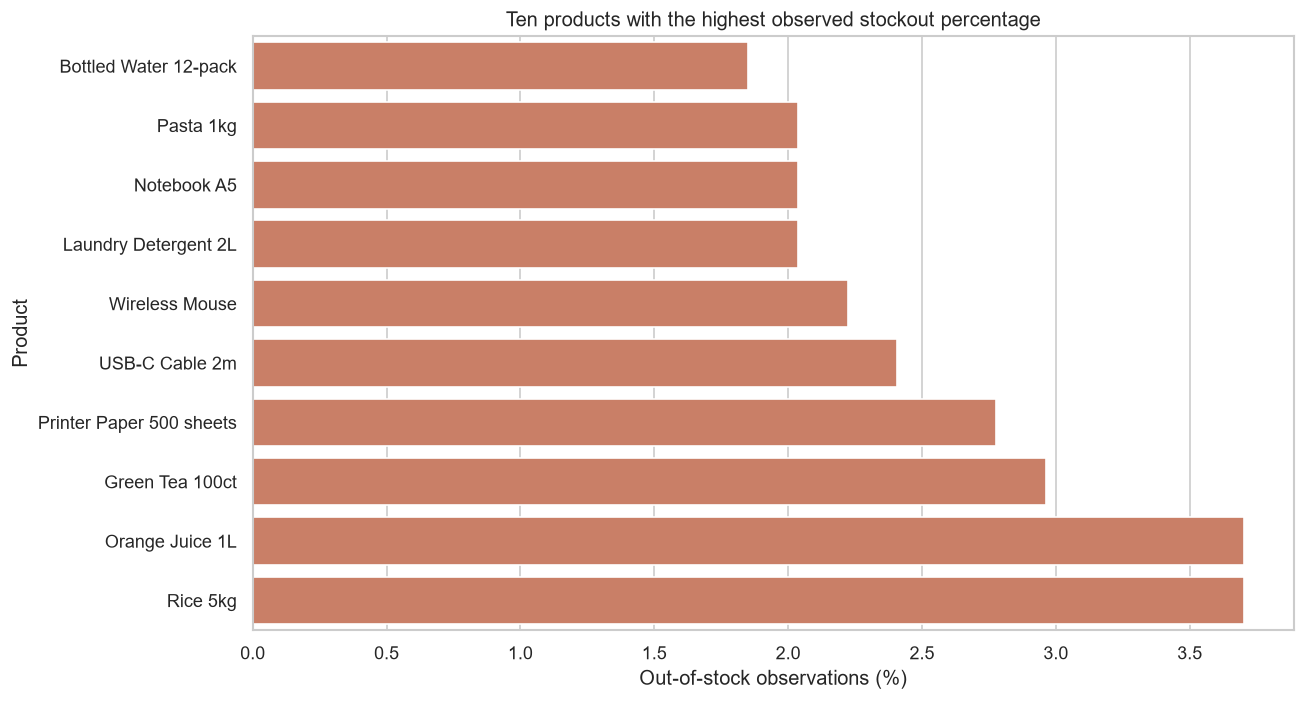

In [3]:
product_summary = (
    df.groupby(["product_id", "product_name"], as_index=False)
      .agg(observations=("availability_status", "size"),
           in_stock_observations=("availability_status", lambda s: s.eq("in_stock").sum()),
           stockout_observations=("availability_status", lambda s: s.eq("out_of_stock").sum()),
           average_stock=("stock_quantity", "mean"),
           observed_restocks=("restock_occurred", "sum"))
)
product_summary["availability_pct"] = 100 * product_summary["in_stock_observations"] / product_summary["observations"]
product_summary["stockout_pct"] = 100 * product_summary["stockout_observations"] / product_summary["observations"]
product_summary = product_summary.sort_values(["stockout_pct", "product_id"], ascending=[False, True])
display(product_summary.head(10).round(2))

fig, ax = plt.subplots(figsize=(11, 6))
plot_data = product_summary.head(10).sort_values("stockout_pct")
sns.barplot(data=plot_data, x="stockout_pct", y="product_name", color="#d97757", ax=ax)
ax.set(title="Ten products with the highest observed stockout percentage",
       xlabel="Out-of-stock observations (%)", ylabel="Product")
plt.tight_layout()
plt.show()
print("Interpretation: bars compare the share of observed rows marked out of stock for these ten products; they describe this synthetic sample only.")

## 4. Store-level inventory performance

Store availability is calculated as the percentage of that store's observations marked `in_stock`. Average stock and observed stockout counts add context; a difference between stores is descriptive and does not identify its cause.

Interpretation: each bar is the in-stock share for one store across its recorded product observations.


,store_id,store_location,observations,stockout_observations,average_stock,observed_restocks,availability_pct
2,S003,"Denver, CO",1800,43,26.33,209,97.61
3,S004,"Atlanta, GA",1800,38,24.02,225,97.89
0,S001,"Austin, TX",1800,37,24.28,244,97.94
5,S006,"Boston, MA",1800,36,25.58,229,98.00
1,S002,"Chicago, IL",1800,31,25.20,222,98.28
4,S005,"Seattle, WA",1800,29,24.53,261,98.39


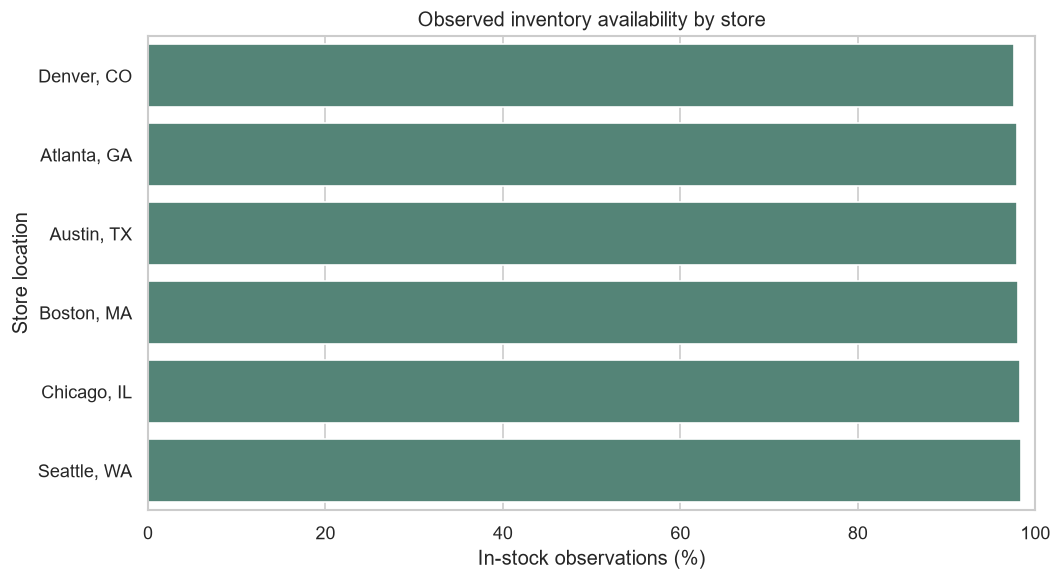

In [4]:
store_summary = (
    df.groupby(["store_id", "store_location"], as_index=False)
      .agg(observations=("availability_status", "size"),
           stockout_observations=("availability_status", lambda s: s.eq("out_of_stock").sum()),
           average_stock=("stock_quantity", "mean"),
           observed_restocks=("restock_occurred", "sum"))
)
store_summary["availability_pct"] = 100 * (1 - store_summary["stockout_observations"] / store_summary["observations"])
store_summary = store_summary.sort_values("availability_pct", ascending=True)
display(store_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=store_summary, x="availability_pct", y="store_location", color="#4c8c7a", ax=ax)
ax.set(title="Observed inventory availability by store",
       xlabel="In-stock observations (%)", ylabel="Store location", xlim=(0, 100))
plt.tight_layout()
plt.show()
print("Interpretation: each bar is the in-stock share for one store across its recorded product observations.")

## 5. Observed restock frequency by product and store

`restock_occurred` is an event recorded on the same row's date. Summing it gives observed restock-event counts in the sample. It is used here only for descriptive EDA, not as a predictor or a future target.

Interpretation: this ranks event counts during the 90-day observation window; counts alone do not show whether a product was adequately stocked.
Interpretation: each heatmap cell counts recorded restock events for one product/store pair.


,product_id,product_name,observed_restock_events
12,P013,Orange Juice 1L,86
17,P018,Notebook A5,84
4,P005,Rice 5kg,80
18,P019,Ballpoint Pens 10-pack,78
15,P016,Wireless Mouse,78
7,P008,Paper Towels 6-pack,76
19,P020,Printer Paper 500 sheets,73
0,P001,Arabica Coffee 500g,72
2,P003,Olive Oil 1L,71
9,P010,Toothpaste 150g,70


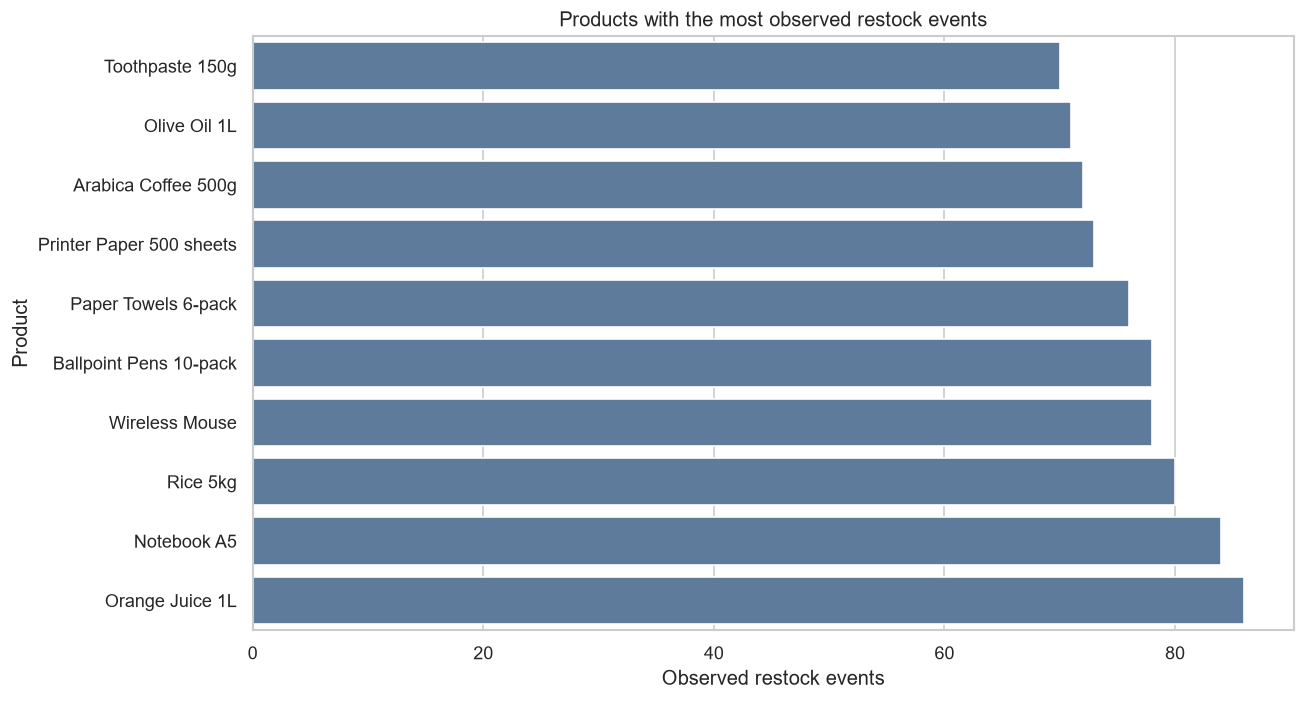

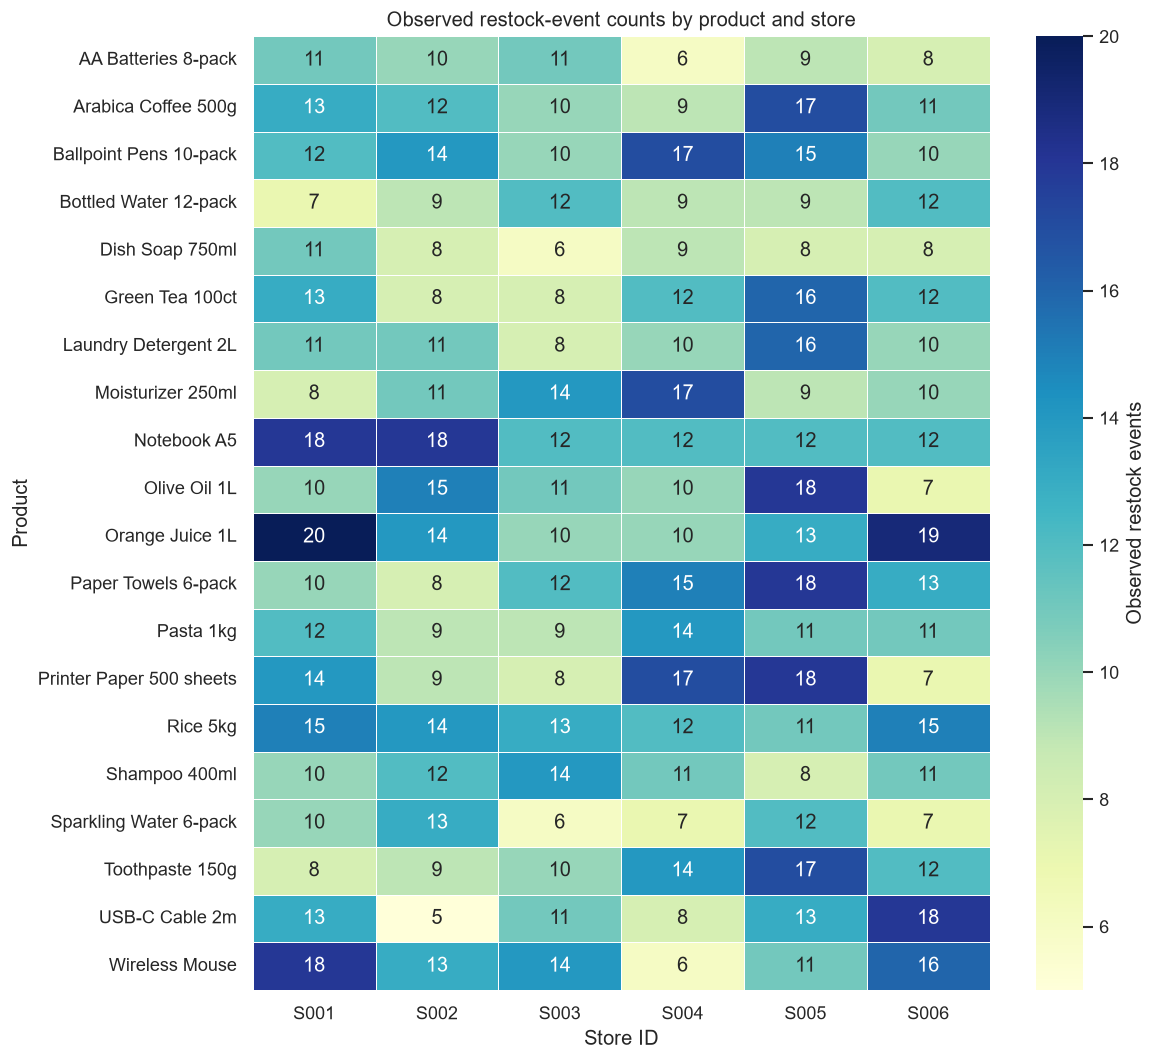

In [5]:
restocks_by_product = (
    df.groupby(["product_id", "product_name"], as_index=False)["restock_occurred"]
      .sum().rename(columns={"restock_occurred": "observed_restock_events"})
      .sort_values("observed_restock_events", ascending=False)
)
display(restocks_by_product.head(10))

fig, ax = plt.subplots(figsize=(11, 6))
plot_data = restocks_by_product.head(10).sort_values("observed_restock_events")
sns.barplot(data=plot_data, x="observed_restock_events", y="product_name", color="#547aa5", ax=ax)
ax.set(title="Products with the most observed restock events",
       xlabel="Observed restock events", ylabel="Product")
plt.tight_layout()
plt.show()
print("Interpretation: this ranks event counts during the 90-day observation window; counts alone do not show whether a product was adequately stocked.")

restock_matrix = df.pivot_table(index="product_name", columns="store_id", values="restock_occurred", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(restock_matrix, cmap="YlGnBu", annot=True, fmt=".0f", linewidths=0.3,
            cbar_kws={"label": "Observed restock events"}, ax=ax)
ax.set(title="Observed restock-event counts by product and store",
       xlabel="Store ID", ylabel="Product")
plt.tight_layout()
plt.show()
print("Interpretation: each heatmap cell counts recorded restock events for one product/store pair.")

## 6. Daily and weekly inventory trends

Daily averages can be noisy, so weekly summaries are also shown. Weeks begin on Monday in UTC. The charts summarize only rows timestamped within each period; they do not use later observations to revise earlier periods.

Interpretation: each point is the mean stock quantity across all records on that UTC date.
Interpretation: this shows the daily share of product/store observations marked in stock.
Interpretation: each point aggregates one calendar week; the line is descriptive and does not establish a trend beyond this generated window.


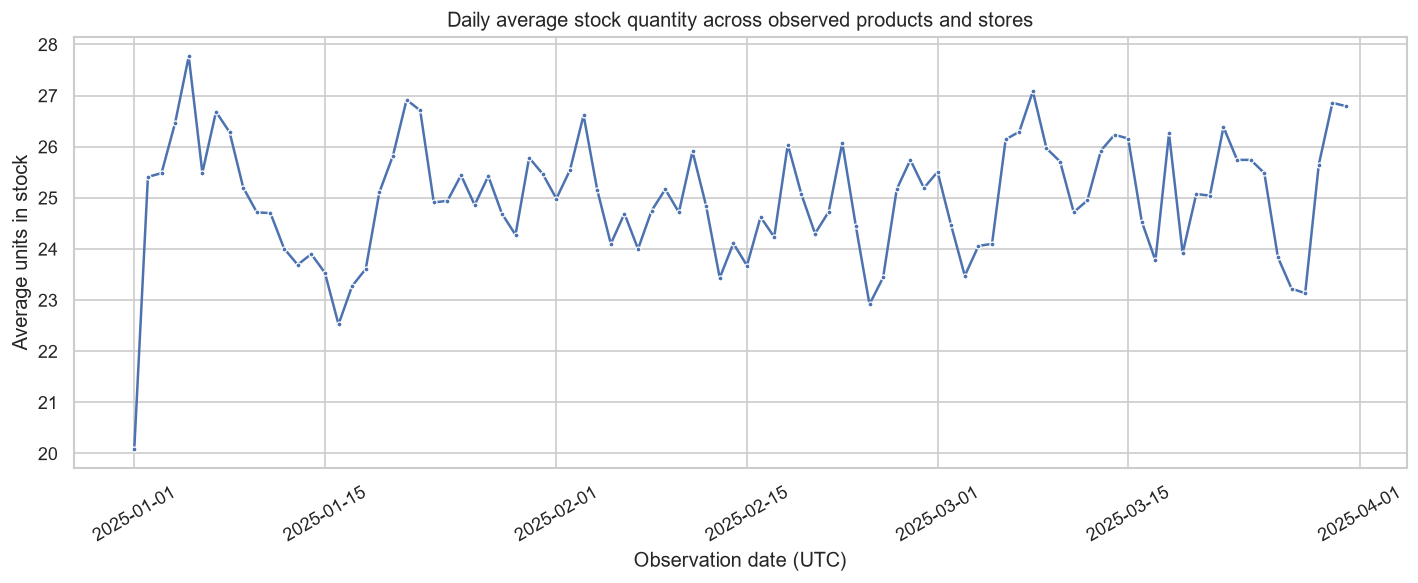

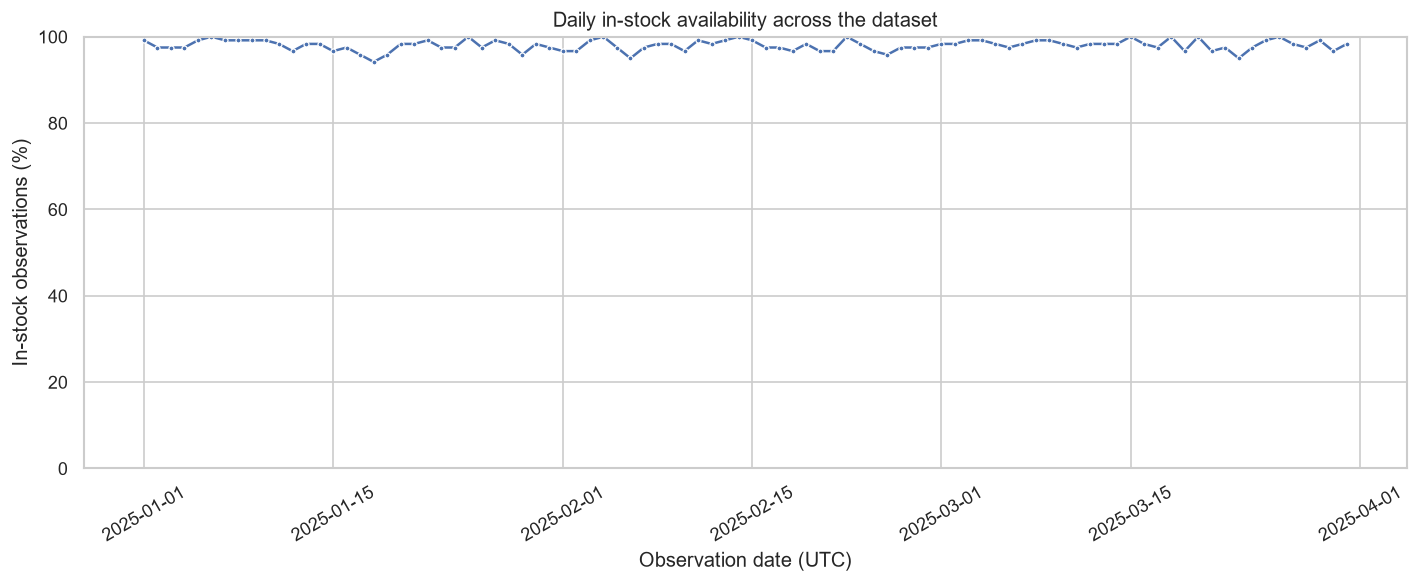

,week_start,average_stock,availability_pct,restock_events
0,2024-12-30,25.04,98.17,105
1,2025-01-06,25.30,98.81,101
2,2025-01-13,23.66,96.67,108
3,2025-01-20,25.66,98.33,106
4,2025-01-27,25.17,97.50,107
5,2025-02-03,24.93,97.98,105
6,2025-02-10,24.47,98.57,106
7,2025-02-17,24.98,97.74,104
8,2025-02-24,24.63,97.38,108
9,2025-03-03,25.30,98.69,110


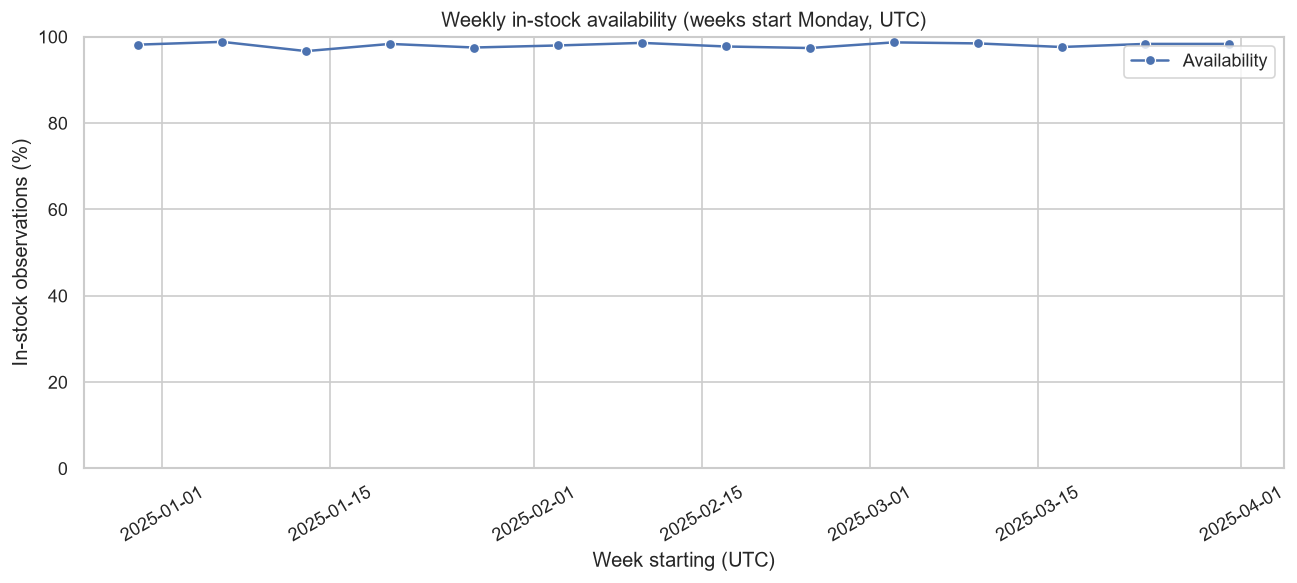

In [6]:
df["day"] = df["timestamp"].dt.floor("D")
daily = df.groupby("day", as_index=False).agg(
    average_stock=("stock_quantity", "mean"),
    availability_pct=("availability_status", lambda s: 100 * s.eq("in_stock").mean()),
    stockout_observations=("availability_status", lambda s: s.eq("out_of_stock").sum()),
    restock_events=("restock_occurred", "sum"),
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=daily, x="day", y="average_stock", marker="o", markersize=3, ax=ax)
ax.set(title="Daily average stock quantity across observed products and stores",
       xlabel="Observation date (UTC)", ylabel="Average units in stock")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
print("Interpretation: each point is the mean stock quantity across all records on that UTC date.")

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=daily, x="day", y="availability_pct", marker="o", markersize=3, ax=ax)
ax.set(title="Daily in-stock availability across the dataset",
       xlabel="Observation date (UTC)", ylabel="In-stock observations (%)", ylim=(0, 100))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
print("Interpretation: this shows the daily share of product/store observations marked in stock.")

df["week_start"] = (df["timestamp"].dt.tz_localize(None).dt.normalize()
                    - pd.to_timedelta(df["timestamp"].dt.day_of_week, unit="D"))
weekly = df.groupby("week_start", as_index=False).agg(
    average_stock=("stock_quantity", "mean"),
    availability_pct=("availability_status", lambda s: 100 * s.eq("in_stock").mean()),
    restock_events=("restock_occurred", "sum"),
)
weekly_display = weekly.copy()
weekly_display["week_start"] = weekly_display["week_start"].dt.strftime("%Y-%m-%d")
display(weekly_display.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=weekly, x="week_start", y="availability_pct", marker="o", ax=ax, label="Availability")
ax.set(title="Weekly in-stock availability (weeks start Monday, UTC)",
       xlabel="Week starting (UTC)", ylabel="In-stock observations (%)", ylim=(0, 100))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
print("Interpretation: each point aggregates one calendar week; the line is descriptive and does not establish a trend beyond this generated window.")

## 7. Stock quantity and availability-status distributions

The histogram shows how often different on-hand quantities appear. The status chart gives the overall split between in-stock and out-of-stock observations. These distributions are shaped by the synthetic generator's assumptions.

Interpretation: taller bins contain stock quantities that occur more often in the processed dataset.
Interpretation: bar heights count rows in each recorded status category.


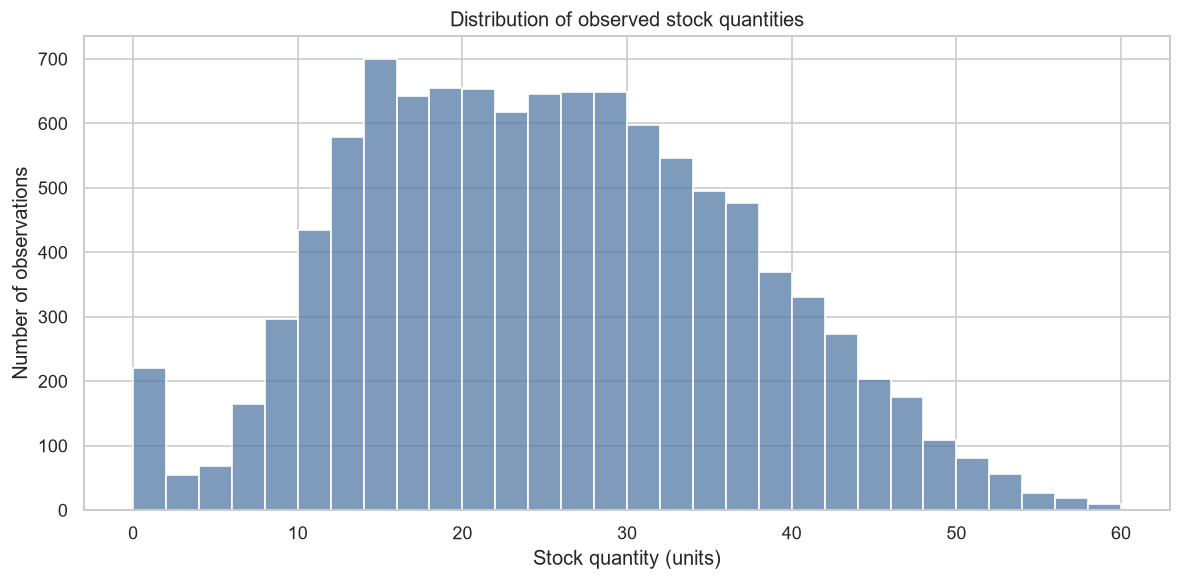

,availability_status,observations,percentage
0,in_stock,10586,98.02
1,out_of_stock,214,1.98


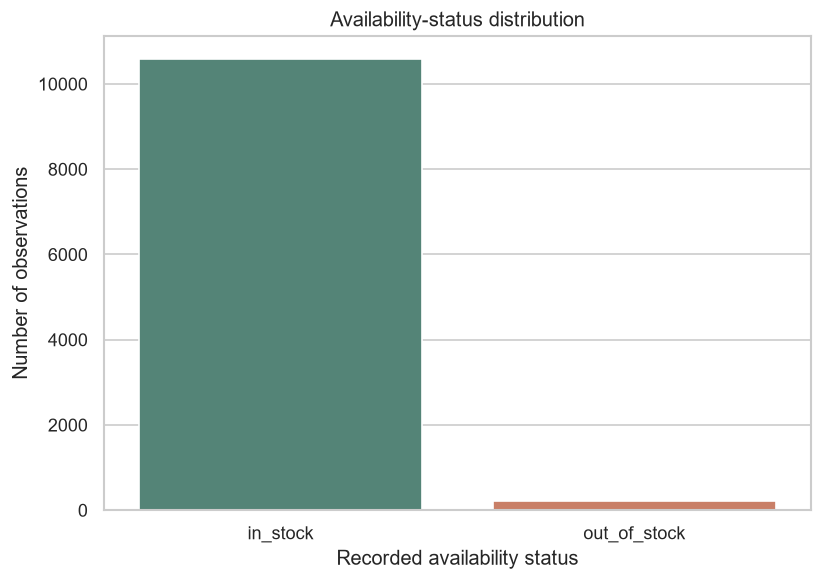

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x="stock_quantity", bins=30, color="#547aa5", edgecolor="white", ax=ax)
ax.set(title="Distribution of observed stock quantities",
       xlabel="Stock quantity (units)", ylabel="Number of observations")
plt.tight_layout()
plt.show()
print("Interpretation: taller bins contain stock quantities that occur more often in the processed dataset.")

status_counts = df["availability_status"].value_counts().reindex(["in_stock", "out_of_stock"], fill_value=0)
status_summary = status_counts.rename_axis("availability_status").reset_index(name="observations")
status_summary["percentage"] = 100 * status_summary["observations"] / len(df)
display(status_summary.round(2))
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=status_summary, x="availability_status", y="observations",
            hue="availability_status", palette={"in_stock": "#4c8c7a", "out_of_stock": "#d97757"},
            legend=False, ax=ax)
ax.set(title="Availability-status distribution",
       xlabel="Recorded availability status", ylabel="Number of observations")
plt.tight_layout()
plt.show()
print("Interpretation: bar heights count rows in each recorded status category.")

## 8. Descriptive relationships among stock, restock history, and availability

The boxplots compare stock and historical fields across availability labels. Historical restock count naturally accumulates over time, so it must be interpreted together with observation date. The scatter plot relates stock quantity to days since the recorded historical restock; early values of that field have an assumed baseline (see limitations below). These are descriptive associations, not causal effects.

Interpretation: boxes summarize the median and spread of each field within each status; historical counts also reflect how late an observation occurs in the window.
Interpretation: each point is one sampled observation; color identifies its availability status. The plot does not imply that elapsed time causes stock levels.


,availability_status,observations,average_stock,median_stock,average_days_since_restock,average_historical_restock_count
0,in_stock,10586,25.49,25.0,4.79,5.82
1,out_of_stock,214,0.00,0.0,7.68,5.86


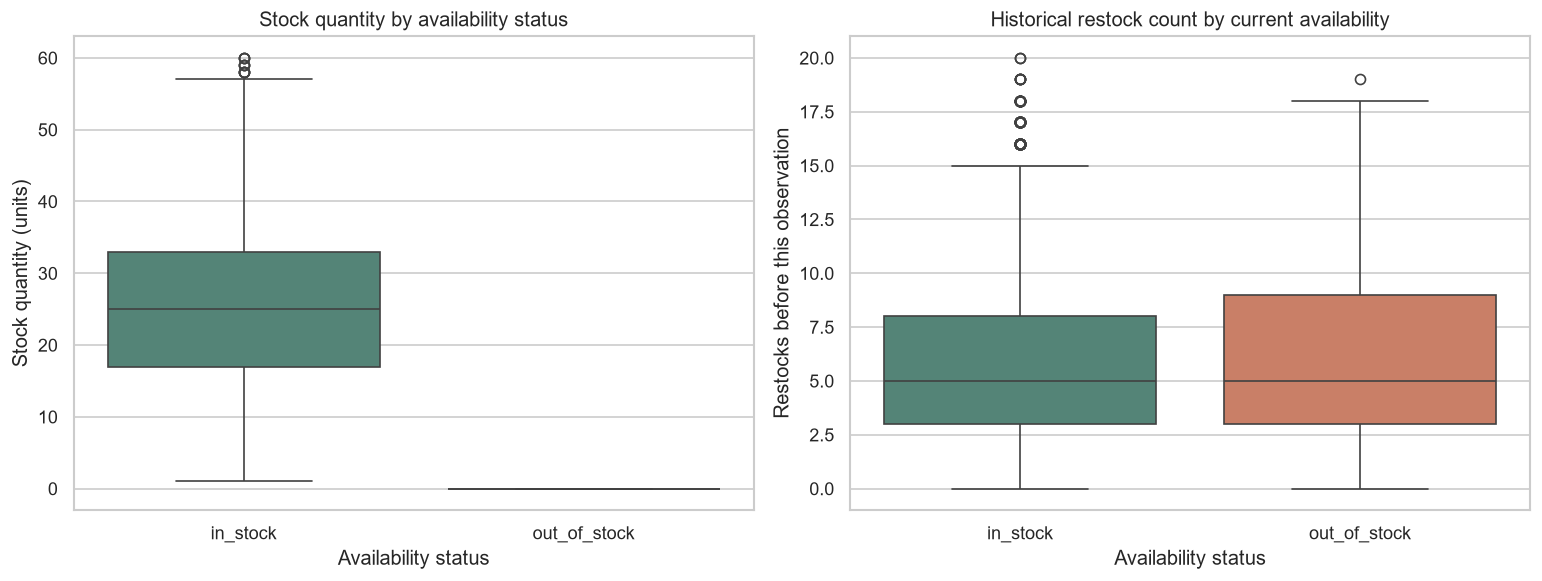

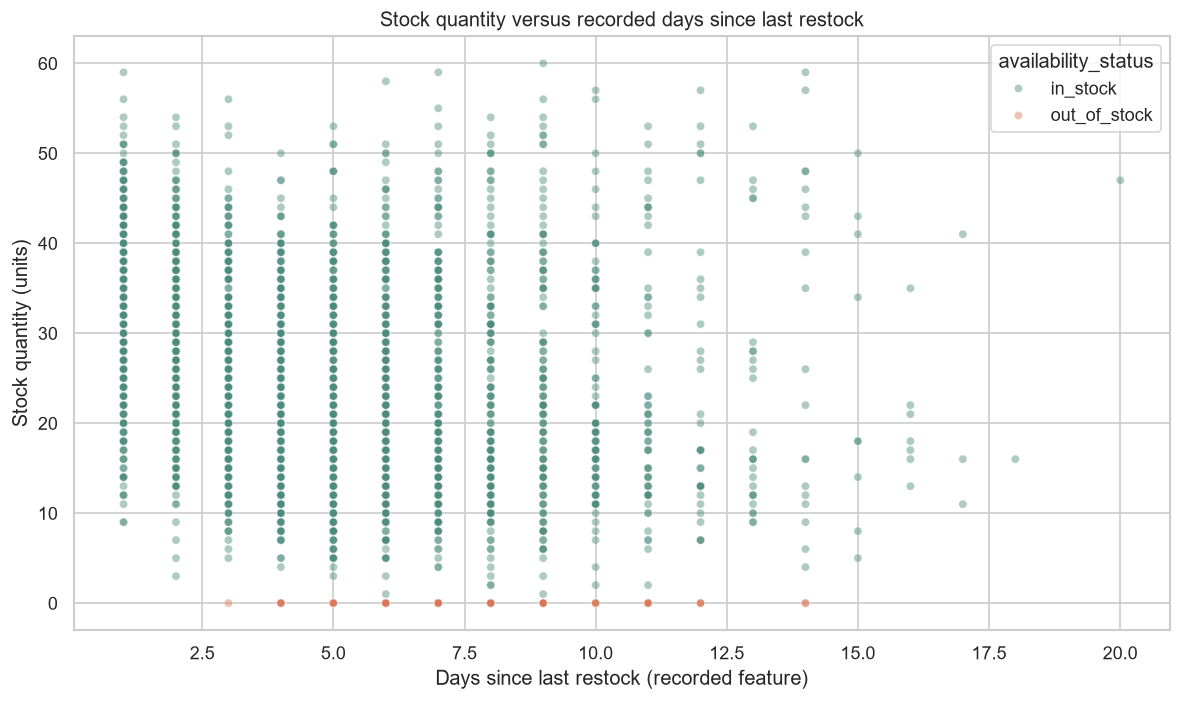

In [8]:
relationship_summary = (
    df.groupby("availability_status", as_index=False)
      .agg(observations=("stock_quantity", "size"),
           average_stock=("stock_quantity", "mean"),
           median_stock=("stock_quantity", "median"),
           average_days_since_restock=("days_since_last_restock", "mean"),
           average_historical_restock_count=("historical_restock_count", "mean"))
)
display(relationship_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x="availability_status", y="stock_quantity", hue="availability_status",
            legend=False, ax=axes[0], palette={"in_stock": "#4c8c7a", "out_of_stock": "#d97757"})
axes[0].set(title="Stock quantity by availability status",
            xlabel="Availability status", ylabel="Stock quantity (units)")
sns.boxplot(data=df, x="availability_status", y="historical_restock_count", hue="availability_status",
            legend=False, ax=axes[1], palette={"in_stock": "#4c8c7a", "out_of_stock": "#d97757"})
axes[1].set(title="Historical restock count by current availability",
            xlabel="Availability status", ylabel="Restocks before this observation")
plt.tight_layout()
plt.show()
print("Interpretation: boxes summarize the median and spread of each field within each status; historical counts also reflect how late an observation occurs in the window.")

sample = df.sample(n=min(3000, len(df)), random_state=42)
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sample, x="days_since_last_restock", y="stock_quantity",
                hue="availability_status", alpha=0.45, s=24,
                palette={"in_stock": "#4c8c7a", "out_of_stock": "#d97757"}, ax=ax)
ax.set(title="Stock quantity versus recorded days since last restock",
       xlabel="Days since last restock (recorded feature)", ylabel="Stock quantity (units)")
plt.tight_layout()
plt.show()
print("Interpretation: each point is one sampled observation; color identifies its availability status. The plot does not imply that elapsed time causes stock levels.")

## 9. Business insights and next questions

The findings below are calculated directly from this synthetic sample. They are evidence about the generated data only. Recommendations are prototype ideas to test against real, operationally validated inventory records.

In [9]:
overall_availability = 100 * df["availability_status"].eq("in_stock").mean()
overall_stockout = 100 - overall_availability
start_date = df["timestamp"].min().date()
end_date = df["timestamp"].max().date()
worst_product = product_summary.iloc[0]
best_store = store_summary.iloc[-1]
worst_store = store_summary.iloc[0]
most_restocked_product = restocks_by_product.iloc[0]
pair_counts = (df.groupby(["product_name", "store_id"], as_index=False)["restock_occurred"].sum()
                 .rename(columns={"restock_occurred": "events"}).sort_values("events", ascending=False))
most_restocked_pair = pair_counts.iloc[0]
weekly_low = weekly.loc[weekly["availability_pct"].idxmin()]
weekly_high = weekly.loc[weekly["availability_pct"].idxmax()]
median_stock = df["stock_quantity"].median()

findings = [
    f"The file contains {len(df):,} synthetic observations for {df['product_id'].nunique()} products and {df['store_id'].nunique()} stores, from {start_date} through {end_date}.",
    f"Overall, {overall_availability:.1f}% of observations are in stock and {overall_stockout:.1f}% are out of stock.",
    f"{worst_product['product_name']} has the largest observed product stockout share in this sample: {worst_product['stockout_pct']:.1f}% ({int(worst_product['stockout_observations'])} of {int(worst_product['observations'])} observations).",
    f"Store availability ranges from {worst_store['availability_pct']:.1f}% at {worst_store['store_location']} to {best_store['availability_pct']:.1f}% at {best_store['store_location']} (a {best_store['availability_pct'] - worst_store['availability_pct']:.1f} percentage-point difference in this sample).",
    f"{most_restocked_product['product_name']} has the most recorded restock events by product: {int(most_restocked_product['observed_restock_events'])}.",
    f"The largest product/store restock count is {int(most_restocked_pair['events'])} for {most_restocked_pair['product_name']} at {most_restocked_pair['store_id']}.",
    f"The lowest and highest weekly availability values are {weekly_low['availability_pct']:.1f}% (week of {weekly_low['week_start'].date()}) and {weekly_high['availability_pct']:.1f}% (week of {weekly_high['week_start'].date()}); weekly summaries vary within this generated window.",
    f"The median observed stock quantity is {median_stock:.0f} units; the distribution is concentrated according to the histogram above.",
]
print("Evidence-based findings (synthetic data):")
for number, finding in enumerate(findings, start=1):
    print(f"{number}. {finding}")

print("\nPotential inventory-management recommendations to evaluate with real data:")
recommendations = [
    "Use product/store availability summaries to prioritize operational audits after confirming the same pattern in retailer records.",
    "Compare store replenishment processes where availability differs, while checking demand, delivery schedules, and assortment before attributing a cause.",
    "Capture a verified pre-window restock timestamp (or an explicit unknown value) so restock-age features have a clear meaning.",
    "Track inventory observations and restock event timestamps consistently, including stockouts and delayed deliveries, before relying on automated alerts.",
]
for item in recommendations:
    print("-", item)

print("\nDataset limitations:")
limitations = [
    "All records are synthetic and do not describe any actual retailer, store, or customer demand.",
    "The generated observation window is only 90 days and has one daily snapshot per product/store.",
    "The first days_since_last_restock values use an assumed baseline because pre-window restock history is unavailable; they are not verified elapsed times.",
    "Restock counts and inventory fluctuations follow generator rules and should not be treated as empirically calibrated operations.",
]
for item in limitations:
    print("-", item)

print("\nQuestions for later machine-learning phases (not tested here):")
questions = [
    "Using only data known at an observation time, how well can we estimate whether a restock occurs during the next 24 hours?",
    "Does a chronological baseline outperform simple heuristics across products and stores on later dates?",
    "Are predicted probabilities calibrated, and how do precision and recall change at different alert thresholds?",
    "Do performance and error rates differ by store or product category on a time-separated test period?",
]
for item in questions:
    print("-", item)

Evidence-based findings (synthetic data):
1. The file contains 10,800 synthetic observations for 20 products and 6 stores, from 2025-01-01 through 2025-03-31.
2. Overall, 98.0% of observations are in stock and 2.0% are out of stock.
3. Rice 5kg has the largest observed product stockout share in this sample: 3.7% (20 of 540 observations).
4. Store availability ranges from 97.6% at Denver, CO to 98.4% at Seattle, WA (a 0.8 percentage-point difference in this sample).
5. Orange Juice 1L has the most recorded restock events by product: 86.
6. The largest product/store restock count is 20 for Orange Juice 1L at S001.
7. The lowest and highest weekly availability values are 96.7% (week of 2025-01-13) and 98.8% (week of 2025-01-06); weekly summaries vary within this generated window.
8. The median observed stock quantity is 24 units; the distribution is concentrated according to the histogram above.

Potential inventory-management recommendations to evaluate with real data:
- Use product/stor